# Visualizing Image Patches and Augmentations

This code was primarily used to **visualize 224×224 image patches** extracted from the original images, along with their **augmented versions**. While initially developed as a standalone visualization tool, parts of this logic were later integrated into the main training pipeline (`trainingOptuna.ipynb`) to dynamically generate patches during training.


### Patch-based Learning Context

In our project, each high-resolution image is decomposed into multiple smaller patches. This **patch-based strategy** is essential because:
- relevant visual patterns are often **localized** rather than global,
- it increases the effective number of training samples,
- and it enables the model to focus on fine-grained structures that may be lost at full resolution.

### Role of Data Augmentation

To address these issues, **data augmentation** plays a crucial role:
- it increases variability without collecting new data,
- improves generalization,
- and reduces overfitting, especially in low-data regimes.

In our case, augmentations are applied directly to patches, amplifying their impact.  
For this reason, it is critical to ensure that augmentations:
- preserve the semantic content of the patch,
- do not introduce unrealistic artifacts,
- and do not alter class-defining features.



In [ ]:
import os
import random
import numpy as np
import torch
from torchvision import transforms
from matplotlib import pyplot as plt
from PIL import Image
import cv2
import albumentations as A
from albumentations.pytorch import ToTensorV2


### PatchDataset definition
This is one of the most important function in our code:
- it creates the patches at fly
- it applyes augmentation
- it normalize for the CNN

**To know more about this function see the TrainingK-Fold_OPTUNA_DOUBLEPATH Notebook**

In [ ]:
# ImageNet normalization statistics 
IMAGENET_MEAN = [0.485, 0.456, 0.406] 
IMAGENET_STD = [0.229, 0.224, 0.225]


class PatchDataset(torch.utils.data.Dataset):

    def __init__(self, images, masks, labels=None,
                 geometric_augmentation=None, fotometric_augmentation=None, normalize_imagenet=False):

        self.images = images          # (N, H, W, 3)
        self.masks = masks            # (N, H, W)
        self.labels = torch.from_numpy(labels).long() if labels is not None else None

        self.geometric_augmentation = geometric_augmentation
        self.fotometric_augmentation = fotometric_augmentation

        if normalize_imagenet:
            self.normalize = transforms.Normalize(
                mean=IMAGENET_MEAN, std=IMAGENET_STD
            )
        else:
            self.normalize = None

    def __len__(self):
        return len(self.images)

    def extract_patches(self, image, mask,
                        patch_size=224, stride=224,
                        mask_thresh=0.02, max_patches=20):

        img_patches = []
        mask_patches = []

        h, w = mask.shape
        total_pixels = patch_size * patch_size

        for y in range(0, h - patch_size + 1, stride):
            for x in range(0, w - patch_size + 1, stride):

                mask_patch = mask[y:y+patch_size, x:x+patch_size]

                if mask_patch.sum() < mask_thresh * total_pixels:
                    continue

                img_patch = image[y:y+patch_size, x:x+patch_size]

                # AUGMENTATION 
                if self.geometric_augmentation:
                    augmentation = self.geometric_augmentation(image=img_patch, mask=mask_patch)
                    img_patch = augmentation["image"]
                    mask_patch = augmentation["mask"]

                # Only on images
                if self.fotometric_augmentation:
                    augmentation = self.fotometric_augmentation(image=img_patch)
                    img_patch = augmentation["image"]

                # to tensor
                img_tensor = torch.from_numpy(img_patch).permute(2,0,1).float() / 255.0
                mask_tensor = torch.from_numpy(mask_patch).unsqueeze(0).float()  

                # Normalize only RGB, it has no sense do it on MASKS
                if self.normalize:
                    img_tensor = self.normalize(img_tensor)

                mask_tensor = mask_tensor.clamp(0, 1)

                img_patches.append(img_tensor)
                mask_patches.append(mask_tensor)

        if len(img_patches) == 0:
            return None, None

        # Limita numero patch
        if len(img_patches) > max_patches:
            idxs = random.sample(range(len(img_patches)), max_patches)
            img_patches = [img_patches[i] for i in idxs]
            mask_patches = [mask_patches[i] for i in idxs]

        return (
            torch.stack(img_patches, dim=0),  
            torch.stack(mask_patches, dim=0)   
        )


    def __getitem__(self, idx):

        image = self.images[idx].copy()
        mask  = self.masks[idx].copy()

        img_patches, mask_patches = self.extract_patches(image, mask)

        if img_patches is None:
            # dummy patch (it can't happen usually)
            img_patches = torch.zeros((1, 3, 224, 224))
            mask_patches = torch.zeros((1, 1, 224, 224))

        if self.labels is None:
            return img_patches, mask_patches
        else:
            return img_patches, mask_patches, self.labels[idx]


In [ ]:
DATA_FOLDER = "train_data_NOSHREK/"  

# Finding all the images
all_imgs = sorted([f for f in os.listdir(DATA_FOLDER) if f.startswith("img_")])

print("Trovate", len(all_imgs), "immagini.")


Trovate 581 immagini.


### Patch and Mask Visualization

This section visualizes paired image and mask patches side by side.  
Displaying both modalities together helps verify spatial alignment, patch extraction correctness, and overall data consistency before training.


In [ ]:
def show_patches_dual(img_patches, mask_patches, max_show=8):
    """
    img_patches : [N,3,H,W] (torch)
    mask_patches: [N,1,H,W] (torch)
    """

    n = min(max_show, img_patches.shape[0])

    fig, axes = plt.subplots(n, 2, figsize=(6, 3 * n))

    if n == 1:
        axes = [axes]

    for i in range(n):
        img = img_patches[i].permute(1, 2, 0).cpu().numpy()
        mask = mask_patches[i][0].cpu().numpy()

        axes[i][0].imshow(img)
        axes[i][0].set_title(f"Image patch {i}")
        axes[i][0].axis("off")

        axes[i][1].imshow(mask, cmap="gray")
        axes[i][1].set_title(f"Mask patch {i}")
        axes[i][1].axis("off")

    plt.tight_layout()
    plt.show()


In [ ]:
def load_pair_from_folder(img_name):
    img_path = os.path.join(DATA_FOLDER, img_name)
    mask_name = img_name.replace("img_", "mask_")
    mask_path = os.path.join(DATA_FOLDER, mask_name)

    img = np.array(Image.open(img_path).convert("RGB"))
    mask = np.array(Image.open(mask_path).convert("L"))

    
    if mask.max() > 1:
        mask = (mask > 0).astype(np.uint8)

    return img, mask


### Geometric Augmentations

Geometric transformations are used to improve **spatial robustness** and enforce invariance to orientation and slight deformations. These augmentation are applied (at the same moment) to original image patches and masks patches.

Example:
img_XXXX_patch_x and mask_XXXX_patch_x --> Both will have clockwise rotation of 10°


These augmentations encourage the model to focus on **structural patterns** rather than absolute pixel positions.

### Photometric Augmentations

Photometric transformations modify image appearance while preserving semantic content:

- **Color jittering** simulates illumination and staining variability.
- **Blur and noise** increase robustness to acquisition artifacts and sensor noise.
- **Gamma and brightness/contrast adjustments** account for exposure differences.
- **Sharpening and CLAHE** enhance local contrast and edge information.
- **Grayscale conversion** encourages the model to rely on texture and structure rather than color alone.

Together, these augmentations reduce overfitting and improve generalization by exposing the model to a broader distribution of plausible visual conditions.


In [ ]:
# Define augmentation for training
geometric_augmentation = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.10, rotate_limit=15, border_mode=0, p=0.5),
    #A.RandomResizedCrop(height=224, width=224, scale=(0.9, 1), ratio=(0.9, 1), p=0.5),
    A.ElasticTransform(alpha=20, sigma=5, alpha_affine=5, border_mode=0, p=0.2)
])

fotometric_augmentation = A.Compose([
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02, p=0.5),
    A.GaussianBlur(blur_limit=(3, 7), p=0.3),
    A.GaussNoise(var_limit=(5.0, 20.0), p=0.3),
    A.RandomGamma(gamma_limit=(80, 120), p=0.3),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.3),
    A.Sharpen(alpha=(0.1, 0.3), lightness=(0.7, 1.0), p=0.2),
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.2),
    A.ToGray(p=0.05),
])




/home/enange/miniconda3/envs/ANN/lib/python3.10/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_277970/3888301791.py:42: UserWarning: Argument(s) 'alpha_affine' are not valid for transform ElasticTransform
  A.ElasticTransform(alpha=20, sigma=5, alpha_affine=5, border_mode=0, p=0.2)
/tmp/ipykernel_277970/3888301791.py:48: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(5.0, 20.0), p=0.3),


### Patch Dataset Inspection with Augmentations

This section randomly samples images and applies the patch extraction pipeline with both geometric and photometric augmentations enabled.  
Image–mask pairs are processed through the dataset to generate patches, which are then inspected visually.  

This step serves as a sanity check to verify correct patch generation, mask alignment, and the effect of augmentations before training the model.



Selected: img_0543.png
Dataset length: 1
Num patches: 9
IMG patch shape : torch.Size([9, 3, 224, 224])
MASK patch shape: torch.Size([9, 1, 224, 224])


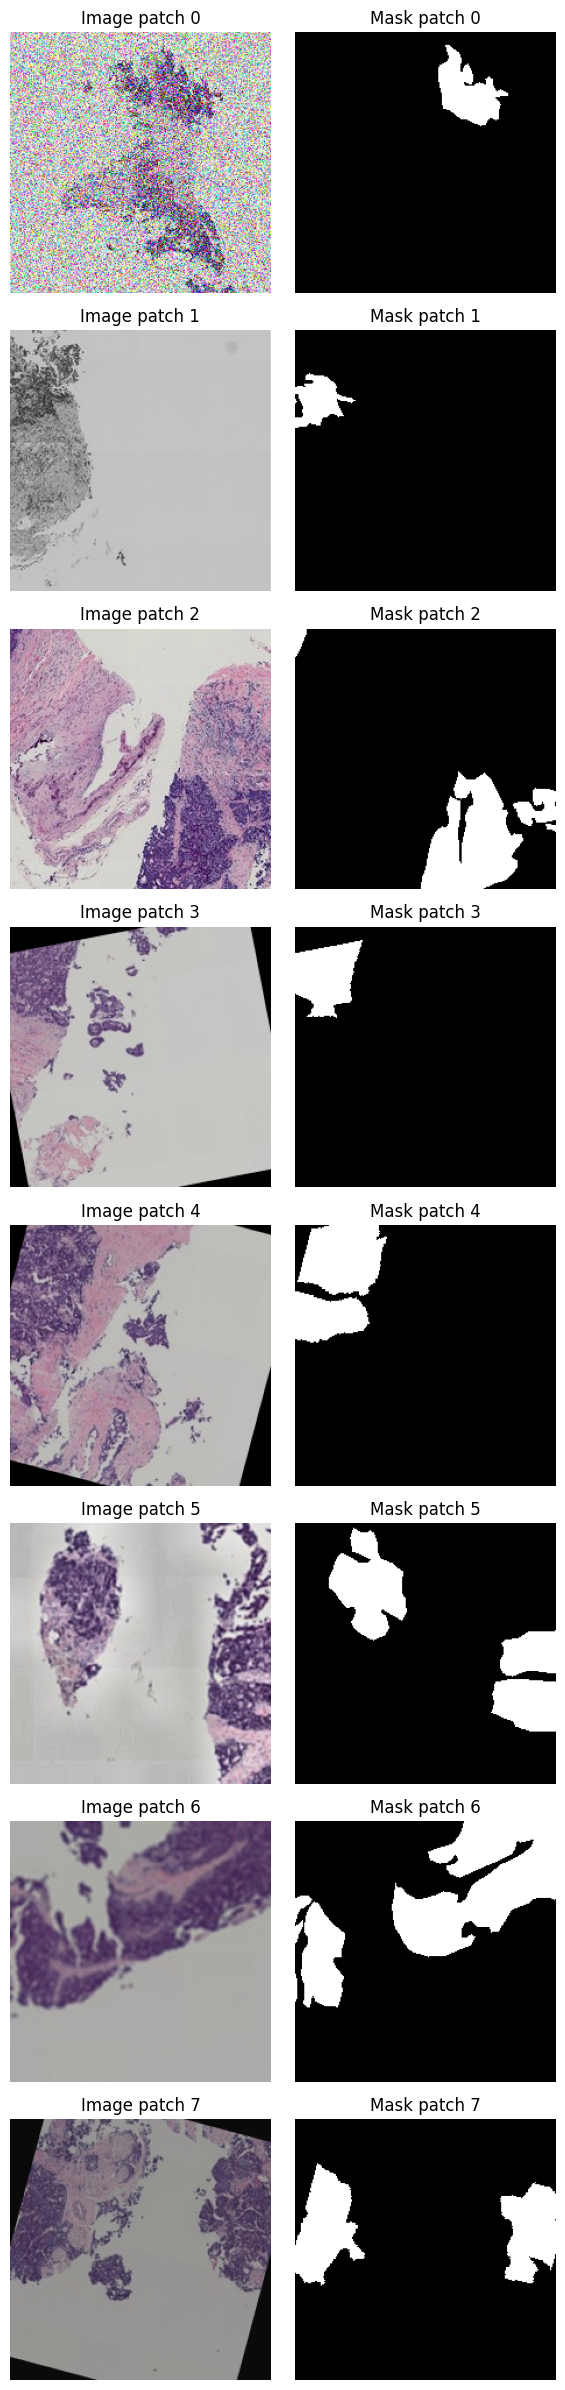


Selected: img_0321.png
Dataset length: 1
Num patches: 6
IMG patch shape : torch.Size([6, 3, 224, 224])
MASK patch shape: torch.Size([6, 1, 224, 224])


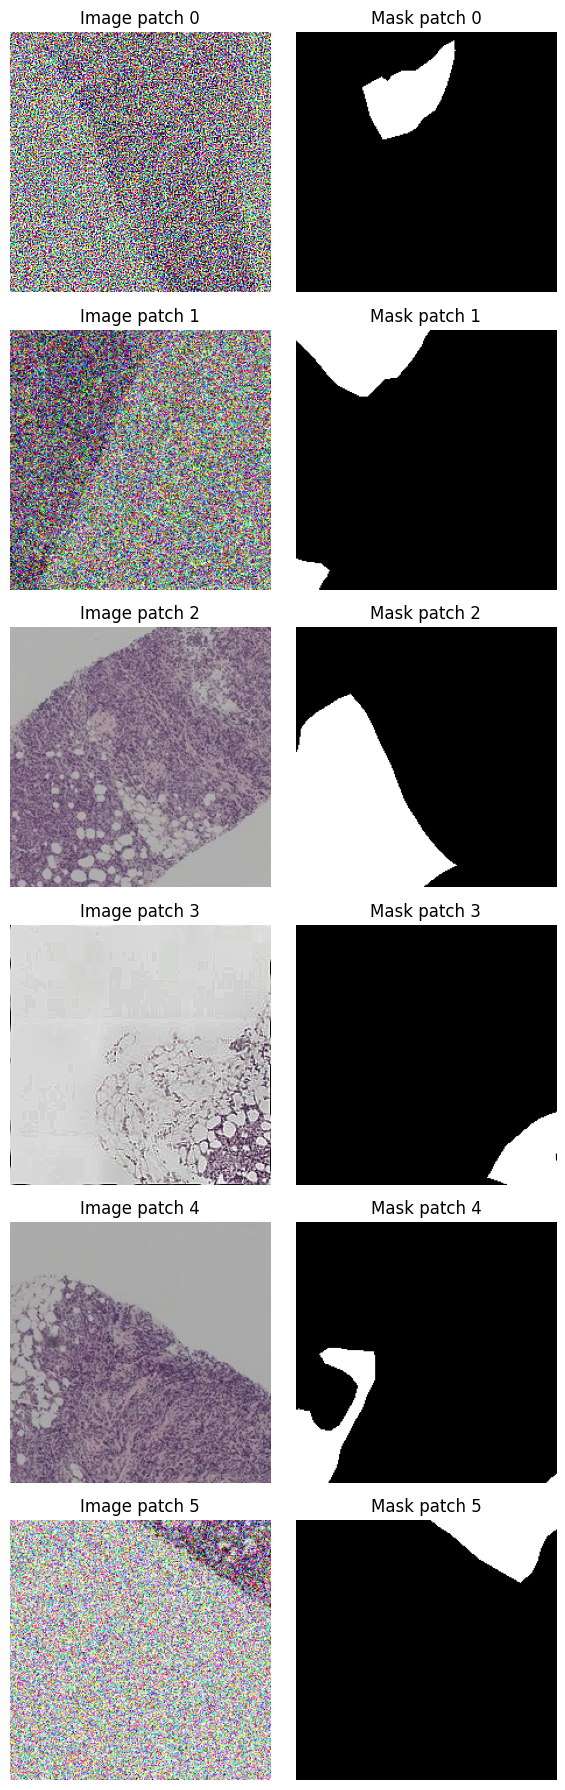


Selected: img_0054.png
Dataset length: 1
Num patches: 2
IMG patch shape : torch.Size([2, 3, 224, 224])
MASK patch shape: torch.Size([2, 1, 224, 224])


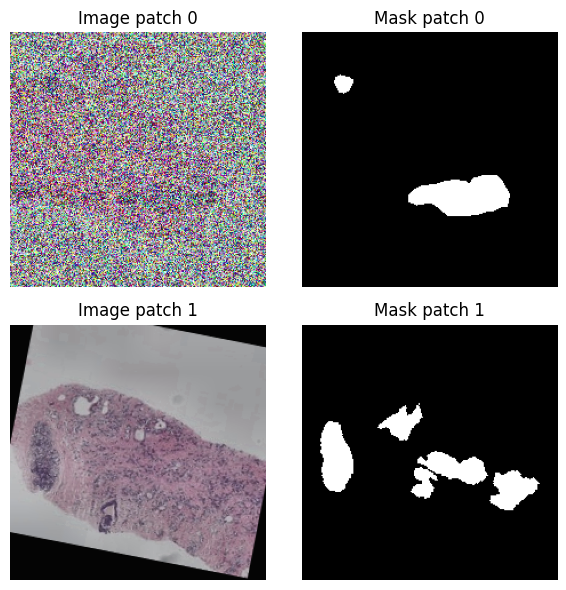


Selected: img_0633.png
Dataset length: 1
Num patches: 6
IMG patch shape : torch.Size([6, 3, 224, 224])
MASK patch shape: torch.Size([6, 1, 224, 224])


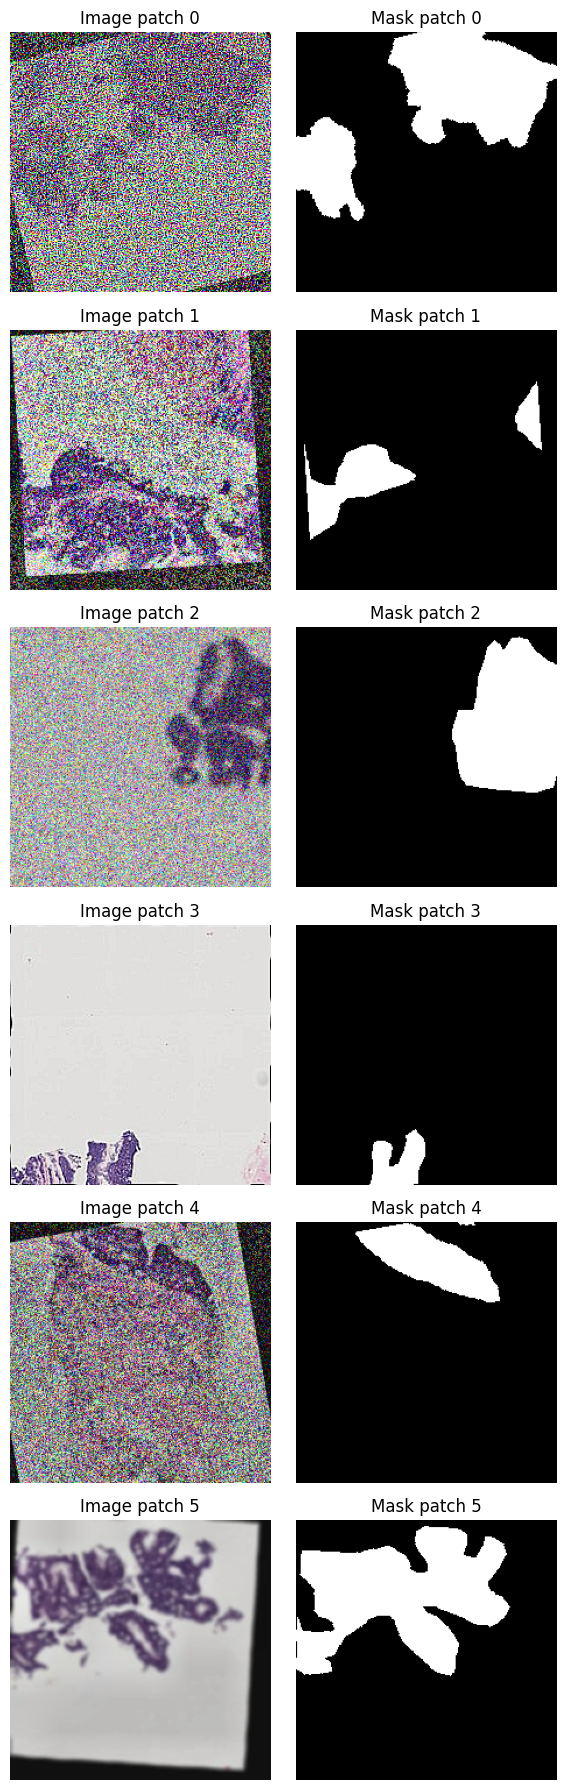


Selected: img_0056.png
Dataset length: 1
Num patches: 2
IMG patch shape : torch.Size([2, 3, 224, 224])
MASK patch shape: torch.Size([2, 1, 224, 224])


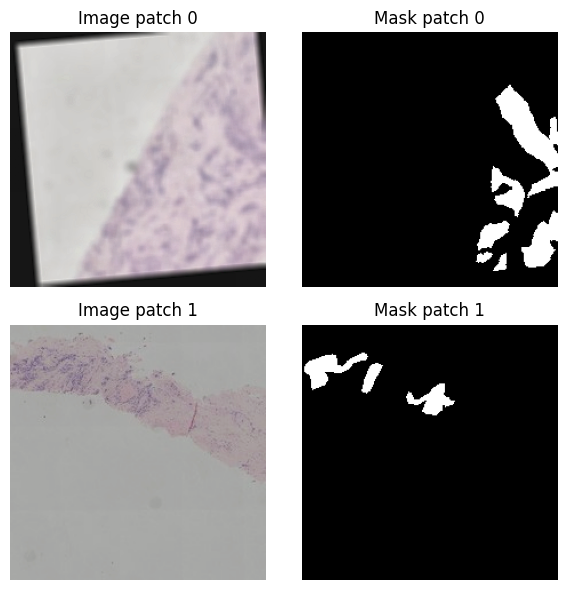

In [ ]:
for _ in range(5):
    img_name = random.choice(all_imgs)
    print("\nSelected:", img_name)

    image, mask = load_pair_from_folder(img_name)

    img_ds = PatchDataset(
        images=[image],
        masks=[mask],
        labels=None,  
        geometric_augmentation=geometric_augmentation,
        fotometric_augmentation=fotometric_augmentation,
        normalize_imagenet=False
    )

    print("Dataset length:", len(img_ds))

    img_patches, mask_patches = img_ds[0]

    print("Num patches:", img_patches.shape[0])
    print("IMG patch shape :", img_patches.shape)
    print("MASK patch shape:", mask_patches.shape)

    # Call the function to visualize the patches
    show_patches_dual(
        img_patches,
        mask_patches,
        max_show=8
    )


